# 1. Project Introduction

**A Feature Selection and Support Vector Machine-Based Framework for High-Accuracy Breast Cancer Diagnosis.**

This notebook compares linear and RBF Support Vector Machine (SVM) kernels with three feature setups (no selection, SelectKBest, and RFE) for breast cancer diagnosis using the Wisconsin Diagnostic Breast Cancer dataset. Model performance is judged mainly by malignant recall and false negatives, since missing a malignant case is the most costly error.


# 2. Importing Required Libraries

In [1]:
%pip install -q ucimlrepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from ucimlrepo import fetch_ucirepo
import joblib


# 3. Loading the Dataset

Load the Wisconsin Diagnostic Breast Cancer dataset from the UCI Machine Learning Repository (dataset ID 17). It contains 569 observations and 30 features. The feature table is stored in `X`, and the diagnosis labels are stored in `y`. See the [official UCI dataset page](https://archive.ics.uci.edu/dataset/17/breast+cancer).

In [2]:
breast_cancer_data = fetch_ucirepo(id=17)
X = breast_cancer_data.data.features.copy()
y = breast_cancer_data.data.targets.squeeze("columns").copy()

print(f"Dataset shape: {X.shape[0]} observations, {X.shape[1]} features")
print("Diagnosis label counts:")
print(y.value_counts())

display(X.head())
display(y.head())


Dataset shape: 569 observations, 30 features
Diagnosis label counts:
Diagnosis
B    357
M    212
Name: count, dtype: int64


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,Diagnosis
0,M
1,M
2,M
3,M
4,M


# 4. Understanding the Dataset

In [3]:
print("Feature data types:")
print(X.dtypes.value_counts())

print("Missing feature values:", X.isna().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

display(X.describe().T)


Feature data types:
float64    30
Name: count, dtype: int64
Missing feature values: 0
Duplicate feature rows: 0


,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


# 5. Data Preprocessing

In [4]:
y_encoded = y.map({"B": 0, "M": 1}).astype("int64")
print(y_encoded.value_counts().sort_index())


Diagnosis
0    357
1    212
Name: count, dtype: int64


# 6. Exploratory Data Analysis

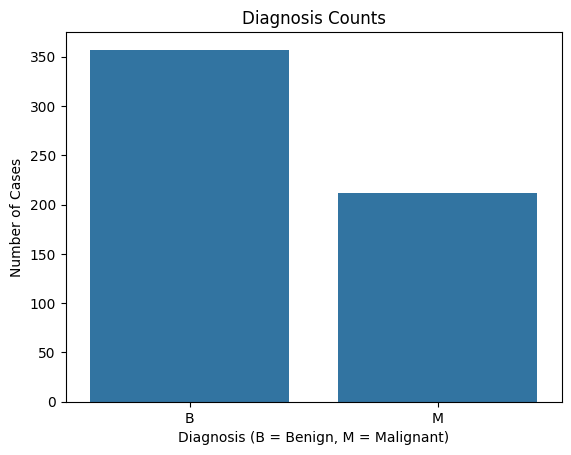

In [5]:
sns.countplot(x=y, order=["B", "M"])
plt.title("Diagnosis Counts")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Number of Cases")
plt.show()


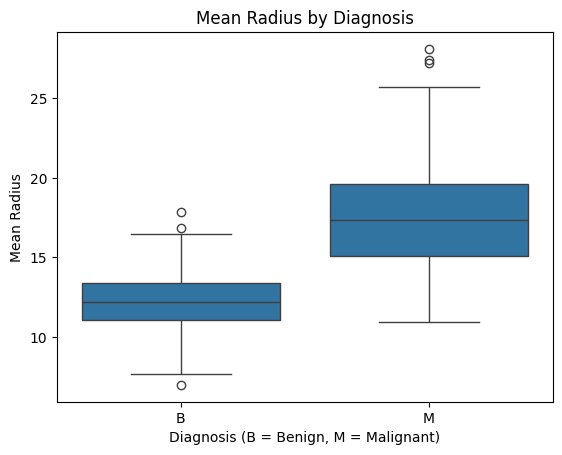

In [6]:
sns.boxplot(x=y, y=X["radius1"], order=["B", "M"])
plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Mean Radius")
plt.show()


# 7. Feature Selection

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC


def make_svm_pipeline(kernel="rbf", C=1.0, selector="passthrough"):
    """Create a scaling, feature-selection, and SVM pipeline."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("selector", selector),
        ("svm", SVC(kernel=kernel, C=C)),
    ])

# 8. Support Vector Machine

A Support Vector Machine (SVM) is a supervised learning method that separates classes by finding a decision boundary with the widest possible margin. The closest training points are called support vectors.

This project compares linear and radial basis function (RBF) SVM kernels. It also compares three feature setups: no feature selection, SelectKBest using an ANOVA F-test, and Recursive Feature Elimination (RFE) using a linear SVM, which removes the least important features step by step. Features are scaled before selection and SVM training. Model settings are compared using stratified five-fold cross-validation on the training data. The parameter C controls the trade-off between a wider margin and penalizing training errors.

# 9. Model Training

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 455
Test samples: 114


In [9]:
import pandas as pd

from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import precision_score, recall_score


def make_svm_pipeline(kernel="rbf", C=1.0, selector="passthrough"):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("selector", selector),
        ("svm", SVC(kernel=kernel, C=C)),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

selector_options = [
    ("No selection", "passthrough"),
    ("SelectKBest", SelectKBest(score_func=f_classif)),
    (
        "RFE",
        RFE(
            estimator=LinearSVC(
                dual=False,
                max_iter=10000,
                random_state=42
            )
        ),
    ),
]

comparison_rows = []
searches = []

for method_name, selector in selector_options:
    for kernel in ["linear", "rbf"]:
        pipeline = make_svm_pipeline(
            kernel=kernel,
            selector=selector
        )

        parameter_grid = {
            "svm__C": [0.1, 1, 10],
            "svm__class_weight": [None, "balanced"],
        }

        if kernel == "rbf":
            parameter_grid["svm__gamma"] = ["scale", "auto"]

        if method_name == "SelectKBest":
            parameter_grid["selector__k"] = [5, 10, 20]
        elif method_name == "RFE":
            parameter_grid["selector__n_features_to_select"] = [5, 10, 20]

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=parameter_grid,
            scoring="recall",
            cv=cv,
            n_jobs=1,
        )

        search.fit(X_train, y_train)

        best_model = search.best_estimator_
        test_predictions = best_model.predict(X_test)

        if method_name == "No selection":
            features_kept = X_train.shape[1]
        else:
            features_kept = int(
                best_model.named_steps["selector"].get_support().sum()
            )

        false_negative_count = int(
            ((y_test.to_numpy() == 1) & (test_predictions == 0)).sum()
        )

        comparison_rows.append({
            "Feature method": method_name,
            "SVM kernel": kernel,
            "Features kept": features_kept,
            "CV malignant recall": search.best_score_,
            "Test malignant recall": recall_score(
                y_test, test_predictions, pos_label=1
            ),
            "Test malignant precision": precision_score(
                y_test, test_predictions, pos_label=1
            ),
            "Test false negatives": false_negative_count,
        })

        searches.append((method_name, kernel, search))


comparison_table = pd.DataFrame(comparison_rows)

display(
    comparison_table
    .sort_values(["Feature method", "SVM kernel"])
    .round(3)
)

best_method, best_kernel, best_search = max(
    searches,
    key=lambda item: item[2].best_score_
)

svm_pipeline = best_search.best_estimator_

print("Best method by cross-validation:", best_method)
print("Best SVM kernel:", best_kernel)
print(
    "Best cross-validation malignant recall:",
    round(best_search.best_score_, 3)
)

,Feature method,SVM kernel,Features kept,CV malignant recall,Test malignant recall,Test malignant precision,Test false negatives
0,No selection,linear,30,0.947,0.905,1.000,4
1,No selection,rbf,30,0.965,0.929,1.000,3
4,RFE,linear,20,0.959,0.929,0.975,3
5,RFE,rbf,5,0.965,0.929,0.929,3
2,SelectKBest,linear,20,0.959,0.976,0.953,1
3,SelectKBest,rbf,20,0.953,0.976,0.976,1


Best method by cross-validation: No selection
Best SVM kernel: rbf
Best cross-validation malignant recall: 0.965


# 10. Model Evaluation

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

y_pred = svm_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(
    "Malignant precision:",
    round(precision_score(y_test, y_pred, pos_label=1), 4)
)
print(
    "Malignant recall:",
    round(recall_score(y_test, y_pred, pos_label=1), 4)
)
print(
    "Malignant F1-score:",
    round(f1_score(y_test, y_pred, pos_label=1), 4)
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign (0)", "Malignant (1)"]
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.9737
Malignant precision: 1.0
Malignant recall: 0.9286
Malignant F1-score: 0.963

Classification report:
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114

Confusion matrix (rows = actual, columns = predicted):
[[72  0]
 [ 3 39]]


# 11. False Negative Analysis

In [11]:
false_negative_mask = y_test.eq(1).to_numpy() & (y_pred == 0)
false_negative_indices = y_test.index[false_negative_mask]

false_negatives = X_test.loc[false_negative_indices].copy()
false_negatives["Actual diagnosis"] = y.loc[false_negative_indices]
false_negatives["Predicted diagnosis"] = "B"

print("False negatives:", len(false_negatives))
display(false_negatives)

False negatives: 3


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Actual diagnosis,Predicted diagnosis
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,109.5,826.4,0.1431,0.3026,0.3194,0.1565,0.2718,0.09353,M,B
73,13.80,15.79,90.43,584.1,0.10070,0.12800,0.07789,0.05069,0.1662,0.06566,...,110.3,812.4,0.1411,0.3542,0.2779,0.1383,0.2589,0.10300,M,B
205,15.12,16.68,98.78,716.6,0.08876,0.09588,0.07550,0.04079,0.1594,0.05986,...,117.7,989.5,0.1491,0.3331,0.3327,0.1252,0.3415,0.09740,M,B


A false negative is a malignant case predicted as benign. Missing a malignant case could delay further assessment, so false negatives are important in this diagnosis task. The model selected by cross-validation (RBF, no feature selection) produced 3 false negatives on the test set. The SelectKBest linear and RBF models each produced 1 on this test split, although cross-validation did not select them as the best models. This difference is only two cases out of 42 malignant samples, so it may reflect this particular split rather than a real advantage. The comparison shows why results from both cross-validation and the held-out test set should be reported.

# 12. Results and Discussion

Five-fold cross-validation selected the RBF SVM with no feature selection, with malignant recall of 0.965. On the held-out test set, this model achieved 97.4% accuracy, 100% malignant precision, 92.9% malignant recall, and 3 false negatives. The SelectKBest linear and RBF models each had 1 false negative on this test split, but cross-validation did not rank them highest. These results show why both cross-validation and test-set results should be reported.

In [12]:
tuned_metrics = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred)],
    "Precision (malignant)": [precision_score(y_test, y_pred, pos_label=1)],
    "Recall (malignant)": [recall_score(y_test, y_pred, pos_label=1)],
    "F1-score (malignant)": [f1_score(y_test, y_pred, pos_label=1)],
    "False negatives": [len(false_negatives)],
}, index=["RBF SVM (no selection)"])

display(tuned_metrics.round(3))

,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant),False negatives
RBF SVM (no selection),0.974,1.0,0.929,0.963,3


# 13. Conclusion

This project compared linear and RBF SVM kernels with three feature setups: no feature selection, SelectKBest, and RFE. Cross-validation selected the RBF SVM with no feature selection (malignant recall 0.965). On the held-out test set it achieved 97.4% accuracy, 100% malignant precision, 92.9% malignant recall, and 3 false negatives. RFE with the RBF kernel matched this cross-validation recall using only 5 of the 30 features, so feature selection gave a simpler model without a clear gain in recall. Both SelectKBest models each produced 1 false negative on this test split, but this is a difference of two cases and was not supported by cross-validation. These results come from one dataset and one train/test split, so further validation is needed before drawing broader conclusions.